# Toy training: EUR chromosome 6

This notebook runs the beacon defender on a synthetic European chromosome 6 cohort. Training goes through the same `main.py` entry point as the paper scripts. The genotypes are simulated, so the run stands in for the 1000 Genomes arrays.

EUR chromosome 6 in the paper is the HLA window on GRCh37, 31.8–33.1 Mb. Honest queries for celiac disease, type 1 diabetes, rheumatoid arthritis, multiple sclerosis, and lupus land in that window. The defender is a TD3 policy gated by a logistic suspicion detector, with a hard rolling mean-absolute-error cap of **0.125926** on the released allele frequencies. Cohort A draws each training beacon from 64 people. The attacker is the alternating-optimization reconstruction of Saleem, et, al.

The constants in the next cell are that recipe at a size that finishes on a laptop. The published EUR chr6 job uses a 50-person beacon, a 1,000-SNP panel, 50 queries, 200 detector episodes per class, and a long TD3 run on the real cohort (`scripts/run_eur_chr6_robustness.py`).


## 1. Settings

`EPISODES` and `CALIBRATION_EPISODES` are the knobs for a longer run. Beacon size, panel size, and query count have to stay within the synthetic cohort built in the next section: cohort A needs a training pool of 64 people whenever the beacon has 64 or fewer members (`env.PUBLISHED_COHORT_A_DRAW`).


In [1]:
from pathlib import Path
import json
import os
import shutil
import subprocess
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "main.py").exists() and (ROOT.parent / "main.py").exists():
    ROOT = ROOT.parent.resolve()
if not (ROOT / "main.py").exists():
    raise FileNotFoundError("Run this notebook from the repository root or from notebooks/.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mplconfig"))

from env import PUBLISHED_COHORT_A_DRAW

SEED = 3
HLA_LO, HLA_HI = 31_800_000, 33_050_000
N_SNPS = 5_000
BEACON_SIZE = 16
ATTACKER_REFERENCE = 16
GENE_SIZE = 64
MAX_QUERIES = 12
EPISODES = 1000
CALIBRATION_EPISODES = 200
MAE_LIMIT = 0.125926
EVAL_ATTACK_EPISODES = 1
EVAL_HONEST_EPISODES = 1

# Cohort A draws the beacon from the first 64 training people. The file also
# keeps a cohort-B holdout of BEACON_SIZE and the attacker reference.
if BEACON_SIZE <= PUBLISHED_COHORT_A_DRAW:
    N_PEOPLE = PUBLISHED_COHORT_A_DRAW + BEACON_SIZE + ATTACKER_REFERENCE
else:
    N_PEOPLE = (2 * BEACON_SIZE) + ATTACKER_REFERENCE

if N_PEOPLE < BEACON_SIZE + ATTACKER_REFERENCE:
    raise ValueError("Need a beacon and an attacker reference.")
if GENE_SIZE > N_SNPS:
    raise ValueError("gene_size cannot exceed the synthetic SNP window.")
if MAX_QUERIES > GENE_SIZE:
    raise ValueError("max_queries cannot exceed gene_size.")
if not (HLA_LO < HLA_HI):
    raise ValueError("HLA window is empty.")

DATA_DIR = ROOT / "data" / "toy" / "EUR"
TOY_ROOT = ROOT / "results" / "toy-eur-chr6"
DETECTOR_DIR = TOY_ROOT / "detector"
TRAIN_DIR = TOY_ROOT / "train"
PREFIX = "eur_chr6"

HIGHLIGHTS = (
    "Device set",
    "Honest disease window",
    "Pinned disease",
    "Sliced ",
    "Loaded ",
    "Baseline F1",
    "anchor",
    "Query mixture",
    "Suspicion gate",
    "Calibrat",
    "HELD-OUT",
    "Saved detector",
    "Episode ",
    "BRA-full checkpoint",
    "Honest utility",
    "Best train",
    "Best eval",
    "Convergence metrics",
    "TD3 update",
    "Skipping TD3",
    "WARNING",
    "Traceback",
    "ValueError",
    "RuntimeError",
)


def show_line(line: str) -> bool:
    return any(fragment in line for fragment in HIGHLIGHTS)


def run_main(args: list[str], log_path: Path) -> str:
    """Stream main.py, keep a full log, and echo the lines that matter."""
    log_path.parent.mkdir(parents=True, exist_ok=True)
    command = [sys.executable, "-u", "main.py", *args]
    print(" ".join(command), flush=True)
    lines: list[str] = []
    with log_path.open("w") as log_file:
        proc = subprocess.Popen(
            command,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )
        assert proc.stdout is not None
        for line in proc.stdout:
            log_file.write(line)
            lines.append(line)
            if show_line(line):
                print(line, end="", flush=True)
        return_code = proc.wait()
    if return_code != 0:
        print("".join(lines[-50:]))
        raise RuntimeError(f"main.py exited {return_code}. Full log: {log_path}")
    return "".join(lines)


def shared_args() -> list[str]:
    return [
        "--data", str(DATA_DIR),
        "--pop_prefix", PREFIX,
        "--gene_size", str(GENE_SIZE),
        "--beacon_size", str(BEACON_SIZE),
        "--corr_size", str(ATTACKER_REFERENCE),
        "--max_queries", str(MAX_QUERIES),
        "--seq-len", str(MAX_QUERIES),
        "--mae-window", str(MAX_QUERIES),
        "--seed", str(SEED),
        "--shuffle-queries",
        "--eval_cohort", "A",
    ]


print(
    f"Synthetic cohort: {N_PEOPLE} people × {N_SNPS} SNPs | "
    f"beacon {BEACON_SIZE} drawn from {PUBLISHED_COHORT_A_DRAW} | "
    f"panel {GENE_SIZE} SNPs | {MAX_QUERIES} queries | "
    f"detector {CALIBRATION_EPISODES}/class | TD3 {EPISODES} episodes"
)
print(f"Data directory: {DATA_DIR}")


Synthetic cohort: 96 people × 5000 SNPs | beacon 16 drawn from 64 | panel 64 SNPs | 12 queries | detector 200/class | TD3 1000 episodes
Data directory: /Users/amir/Documents/misc/beacon-defense-RA/data/toy/EUR


## 2. Synthetic HLA cohort

The files use the same names as `data/EUR/eur_chr6_*`:

- `eur_chr6_cleaned_binary.npy` — people by SNP, alleles in {0, 1}
- `eur_chr6_cleaned_mafs.npy` — population allele frequency of each SNP
- `eur_chr6_snp_manifest.npz` — hg19 position and rsID of each SNP

Alleles inside a block share a latent factor, so neighboring markers are correlated. That is the linkage the reconstruction attack uses. Each disease-catalog rsID on chromosome 6 is written onto the nearest grid marker. Grid spacing is a few hundred base pairs, inside the 200 kb window the honest-query resolver searches.

Row order matches `build_binary_cohort`. The leading 64 rows are the cohort A training pool. The next block is the cohort B holdout (unused while training on cohort A). The last rows are the attacker's public reference.


Wrote /Users/amir/Documents/misc/beacon-defense-RA/data/toy/EUR
  binary (96, 5000)   mafs (5000,)   grid spacing 250 bp
  cohort A pool: rows [0, 64)
  cohort B holdout: rows [64, 80)
  attacker reference: rows [80, 96)
  MAF strata: Common 1111, Highly-Common 898, Low-Freq 700, Rare 898, Ultra-Rare 1393
  planted rsIDs: rs3131379, rs3135388, rs660895, rs9272723, rs2647044, rs2858331, rs424232, rs2187668, rs4988889, rs7775228, rs9272219


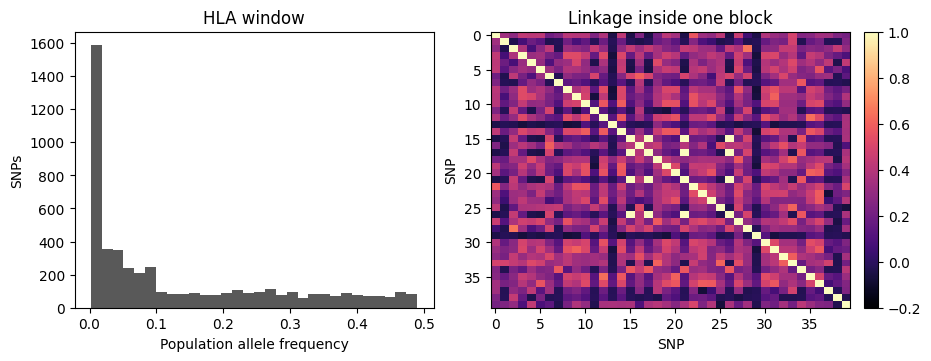

In [2]:
import numpy as np
from scipy.stats import norm

from helpers.disease_catalog import DISEASE_CATALOG
from helpers.snp_manifest import (
    SnpManifest,
    honest_bp_window_indices,
    load_manifest,
    save_manifest,
)
from helpers.snp_stratification import assign_strata

rng = np.random.default_rng(SEED)
positions = np.linspace(HLA_LO, HLA_HI, N_SNPS).astype(np.int64)
for i in range(1, N_SNPS):
    if positions[i] <= positions[i - 1]:
        positions[i] = positions[i - 1] + 1
rsids = np.array([f"rs{8_000_000 + i}" for i in range(N_SNPS)], dtype=object)

catalog = []
seen = set()
for disease in DISEASE_CATALOG:
    for locus in disease.loci:
        if locus.chromosome != 6 or locus.rsid in seen:
            continue
        seen.add(locus.rsid)
        catalog.append(locus)
catalog.sort(key=lambda locus: (locus.position, locus.rsid))

used: set[int] = set()
for locus in catalog:
    guess = int(np.argmin(np.abs(positions.astype(np.int64) - locus.position)))
    idx = None
    for dist in range(N_SNPS):
        candidates = (guess,) if dist == 0 else (guess + dist, guess - dist)
        for candidate in candidates:
            if 0 <= candidate < N_SNPS and candidate not in used:
                idx = candidate
                break
        if idx is not None:
            break
    if idx is None:
        raise RuntimeError(f"No free marker for {locus.rsid}")
    used.add(idx)
    rsids[idx] = locus.rsid

quotas = np.array([0.28, 0.18, 0.14, 0.22, 0.18])
counts = np.floor(quotas * N_SNPS).astype(int)
counts[-1] = N_SNPS - int(counts[:-1].sum())
bands = ((0.002, 0.01), (0.011, 0.05), (0.051, 0.10), (0.101, 0.30), (0.301, 0.49))
mafs = np.concatenate([
    rng.uniform(lo, hi, size=int(n)) for (lo, hi), n in zip(bands, counts)
])
rng.shuffle(mafs)
for idx in used:
    mafs[idx] = rng.uniform(0.12, 0.28)

n_per_block = 200
n_blocks = int(np.ceil(N_SNPS / n_per_block))
block_id = np.minimum(np.arange(N_SNPS) // n_per_block, n_blocks - 1)
factors = rng.normal(size=(N_PEOPLE, n_blocks))
noise = rng.normal(size=(N_PEOPLE, N_SNPS))
rho = 0.85
liability = rho * factors[:, block_id] + np.sqrt(1.0 - rho ** 2) * noise
thresholds = norm.ppf(np.clip(1.0 - mafs, 1e-6, 1.0 - 1e-6))
genotypes = (liability > thresholds).astype(np.float32)

DATA_DIR.mkdir(parents=True, exist_ok=True)
np.save(DATA_DIR / f"{PREFIX}_cleaned_mafs.npy", mafs.astype(np.float64))
np.save(DATA_DIR / f"{PREFIX}_cleaned_binary.npy", genotypes)
manifest = SnpManifest(
    prefix=PREFIX,
    chromosome=6,
    n_individuals=N_PEOPLE,
    positions=positions,
    rsids=rsids,
    alt_counts=genotypes.sum(axis=0).astype(np.int32),
)
save_manifest(manifest, str(DATA_DIR))

loaded = load_manifest(str(DATA_DIR), PREFIX)
window = honest_bp_window_indices(loaded, PREFIX)
if loaded is None or window is None or window.size != N_SNPS:
    raise RuntimeError("Synthetic SNPs fell outside the HLA window main.py trains on.")
missing = [locus.rsid for locus in catalog if loaded.lookup_rsid(locus.rsid) is None]
if missing:
    raise RuntimeError(f"Catalog rsIDs missing from the manifest: {missing}")

spacing = int(np.median(np.diff(positions)))
strata, stratum_counts = np.unique(assign_strata(mafs), return_counts=True)
print(f"Wrote {DATA_DIR}")
print(f"  binary {genotypes.shape}   mafs {mafs.shape}   grid spacing {spacing} bp")
print(f"  cohort A pool: rows [0, {PUBLISHED_COHORT_A_DRAW})")
print(f"  cohort B holdout: rows [{PUBLISHED_COHORT_A_DRAW}, {PUBLISHED_COHORT_A_DRAW + BEACON_SIZE})")
print(f"  attacker reference: rows [{N_PEOPLE - ATTACKER_REFERENCE}, {N_PEOPLE})")
print("  MAF strata: " + ", ".join(f"{name} {int(n)}" for name, n in zip(strata, stratum_counts)))
print(f"  planted rsIDs: {', '.join(locus.rsid for locus in catalog)}")

import matplotlib.pyplot as plt

block = np.flatnonzero(block_id == 0)
block = block[genotypes[:, block].std(axis=0) > 0][:40]
if block.size < 2:
    raise RuntimeError("First linkage block does not have two variable SNPs.")
linkage = np.corrcoef(genotypes[:, block].T)

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.5), constrained_layout=True)
axes[0].hist(mafs, bins=30, color="0.35")
axes[0].set_xlabel("Population allele frequency")
axes[0].set_ylabel("SNPs")
axes[0].set_title("HLA window")
image = axes[1].imshow(linkage, vmin=-0.2, vmax=1.0, cmap="magma", aspect="auto")
axes[1].set_title("Linkage inside one block")
axes[1].set_xlabel("SNP")
axes[1].set_ylabel("SNP")
fig.colorbar(image, ax=axes[1], fraction=0.046, pad=0.04)
plt.show()


## 3. Suspicion detector

The detector is a logistic regression on the query stream. Calibration runs honest disease-panel episodes against mixed reconstruction episodes with the beacon silenced, so this step does no genome reconstruction. The paper uses 200 episodes per class and a 10% honest false-positive budget. Here the episode count is `CALIBRATION_EPISODES`.

Mixed queries on this panel are mostly common SNPs plus a few rare ones, while honest queries hit the planted HLA markers. The two classes separate more cleanly here than they do on 1000 Genomes, so a held-out AUC near 1 is expected at this scale.


In [3]:
if DETECTOR_DIR.exists():
    shutil.rmtree(DETECTOR_DIR)

detector_log = run_main(
    [
        "--calibrate-detector",
        "--calibration-episodes", str(CALIBRATION_EPISODES),
        "--detector-fpr-budget", "0.10",
        "--no-svd-embeddings",
        "--results-dir", str(DETECTOR_DIR),
        *shared_args(),
    ],
    TOY_ROOT / "detector.log",
)

detector_path = DETECTOR_DIR / "suspicion_detector.json"
detector = json.loads(detector_path.read_text())
print(
    f"threshold {detector['threshold']:.3f} | "
    f"step AUC {detector['auc']:.3f} | "
    f"episode AUC {float(detector.get('episode_auc', float('nan'))):.3f} | "
    f"held-out honest FPR {detector['honest_fpr']:.3f} | "
    f"held-out mixed TPR {detector['mixed_tpr']:.3f}"
)
print(f"Saved {detector_path}")


/Users/amir/Documents/misc/beacon-defense-RA/.venv/bin/python -u main.py --calibrate-detector --calibration-episodes 200 --detector-fpr-budget 0.10 --no-svd-embeddings --results-dir /Users/amir/Documents/misc/beacon-defense-RA/results/toy-eur-chr6/detector --data /Users/amir/Documents/misc/beacon-defense-RA/data/toy/EUR --pop_prefix eur_chr6 --gene_size 64 --beacon_size 16 --corr_size 16 --max_queries 12 --seq-len 12 --mae-window 12 --seed 3 --shuffle-queries --eval_cohort A
Device set to : Apple Metal (MPS)
Device set to : Apple Metal (MPS)
 Honest disease window: 5,000 SNPs (chr6 31,800,000–33,050,000 bp)
 Pinned disease catalog SNPs in pool: 11/11 in-window loci (pool size=64)
 Sliced 64 functional SNPs from 5,000 viable candidates.
Loaded 80 individuals and 64 SNPs.
--- Calibrating online adversary detector (200 honest + 200 mixed query-stream episodes, FPR budget 10%) ---
Calibration threshold=-0.6532 | calibration honest FPR=0.100 | calibration mixed TPR=1.000
HELD-OUT TEST: step

## 4. TD3 training

This is the EUR chr6 training command from `scripts/run_eur_chr6_robustness.py`, with the sizes from section 1. The reward is the sparse terminal objective used for the paper: reconstruction F1 and clinical error, plus a penalty when the MAE cap clips the action. Tokens carry rarity, linkage, and attacker-knowledge features. `--bra-fast` shortens the reconstruction inside each training episode. The anchor printed at startup is reconstruction F1 when the beacon adds no noise. The checkpoint at the end scores the frozen policy with the full attack, once on mixed queries and once on an honest disease panel.

`main.py` waits for 500 replay transitions before the first gradient step. This run lowers that floor so a short episode budget still updates the actor.


In [4]:
import re

if TRAIN_DIR.exists():
    shutil.rmtree(TRAIN_DIR)

buffer_warmup = MAX_QUERIES * 3
eval_every = 10 if EPISODES >= 10 else EPISODES

train_log = run_main(
    [
        *shared_args(),
        "--episodes", str(EPISODES),
        "--mae-limit", f"{MAE_LIMIT:.6f}",
        "--no-mae-limit-ramp",
        "--hard-mae-budget",
        "--sparse-reward",
        "--f1-reward-scale", "400",
        "--budget-inefficiency-tax", "1.0",
        "--f1-overbaseline-penalty", "0",
        "--proxy-reward-scale", "0",
        "--reward-normalize-scale", "1.0",
        "--reward-clip", "200",
        "--cer-penalty-weight", "500",
        "--rarity-token-features",
        "--ld-token-features",
        "--ld-history-k", "4",
        "--ld-panel-k", "4",
        "--attacker-knowledge-features",
        "--attacker-knowledge-dim", "8",
        "--no-svd-embeddings",
        "--eval_utility",
        "--bra-fast",
        "--buffer-warmup", str(buffer_warmup),
        "--eval-freq", str(eval_every),
        "--eval-episodes", str(EVAL_ATTACK_EPISODES),
        "--honest-eval-episodes", str(EVAL_HONEST_EPISODES),
        "--results-dir", str(TRAIN_DIR),
        "--run_name", "eur-chr6-toy",
        "--suspicion-detector-path", str(DETECTOR_DIR / "suspicion_detector.json"),
        "--baseline-cache-dir", str(TOY_ROOT / "baseline-cache"),
    ],
    TOY_ROOT / "train.log",
)

anchor_match = re.findall(
    r"BRA-full anchor \(checkpoints/eval\):\s*([0-9.]+)",
    train_log,
)
if not anchor_match:
    anchor_match = re.findall(r"0% Noise Baseline F1\s*:\s*([0-9.]+)", train_log)
ANCHOR_F1 = float(anchor_match[-1]) if anchor_match else None
if ANCHOR_F1 is None:
    print("Startup anchor was not found in the log.")
else:
    print(f"0% noise reconstruction F1 anchor: {ANCHOR_F1:.4f}")


/Users/amir/Documents/misc/beacon-defense-RA/.venv/bin/python -u main.py --data /Users/amir/Documents/misc/beacon-defense-RA/data/toy/EUR --pop_prefix eur_chr6 --gene_size 64 --beacon_size 16 --corr_size 16 --max_queries 12 --seq-len 12 --mae-window 12 --seed 3 --shuffle-queries --eval_cohort A --episodes 1000 --mae-limit 0.125926 --no-mae-limit-ramp --hard-mae-budget --sparse-reward --f1-reward-scale 400 --budget-inefficiency-tax 1.0 --f1-overbaseline-penalty 0 --proxy-reward-scale 0 --reward-normalize-scale 1.0 --reward-clip 200 --cer-penalty-weight 500 --rarity-token-features --ld-token-features --ld-history-k 4 --ld-panel-k 4 --attacker-knowledge-features --attacker-knowledge-dim 8 --no-svd-embeddings --eval_utility --bra-fast --buffer-warmup 36 --eval-freq 10 --eval-episodes 1 --honest-eval-episodes 1 --results-dir /Users/amir/Documents/misc/beacon-defense-RA/results/toy-eur-chr6/train --run_name eur-chr6-toy --suspicion-detector-path /Users/amir/Documents/misc/beacon-defense-RA/r

## 5. Reading the run

Reconstruction F1 is the privacy number: lower means the attack recovered less of the beacon. Mean absolute noise is the utility number. Points are training episodes, colored by the query policy sampled that episode (about 80% mixed, 20% honest).

The dashed line on the left is the 0% noise anchor, measured on mixed queries before training. Compare mixed-episode F1 to that line. Honest episodes query a different set of SNPs, so their F1 is a separate reconstruction; the honest check is the noise, which should sit near zero when the gate treats the stream as a researcher. The dashed line on the right is the MAE cap. Mixed episodes are allowed to spend that budget.

Exploration in `main.py` stays high until episode 100. The numbers under the training averages are the frozen policy saved in `weights_best_eval`, the checkpoint with the lowest mixed-attack F1. The scatter itself is every training episode. The paper's curves come from the full episode budget on the real cohort.


Best eval weights: /Users/amir/Documents/misc/beacon-defense-RA/results/toy-eur-chr6/train/run0/weights_best_eval
Frozen policy at episode 110: mixed F1 0.3939 (anchor 0.7100, lift +0.3160) | mixed MAE 0.1250 | honest MAE 0.0000 | honest F1 0.7429
Training-episode means: /Users/amir/Documents/misc/beacon-defense-RA/results/toy-eur-chr6/train/run0/convergence_metrics.csv
                          mae  clinical_error_ratio
episode_attacker_type                              
honest                 0.0041                0.0023
mixed                  0.1211                0.0827


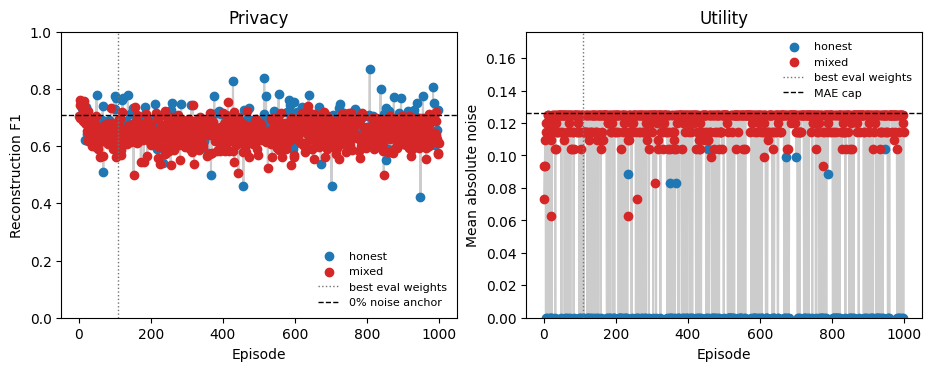

In [6]:
import re

import pandas as pd
import matplotlib.pyplot as plt

def read_best_eval(run_dir: Path) -> dict[str, float]:
    """Metrics written next to the actor when mixed eval F1 set a new low."""
    path = run_dir / "weights_best_eval" / "best_metrics.txt"
    if not path.is_file():
        raise FileNotFoundError(f"No best-eval weights under {run_dir}")
    text = path.read_text()

    def grab(label: str) -> float:
        match = re.search(rf"{re.escape(label)}:\s*([+-]?[0-9.]+)", text)
        if match is None:
            raise ValueError(f"{path} is missing {label}")
        return float(match.group(1))

    episode = re.search(r"Eval after episode (\d+)", text)
    if episode is None:
        raise ValueError(f"{path} is missing the eval episode")
    return {
        "episode": float(episode.group(1)),
        "mixed_f1": grab("MIXED Eval F1"),
        "anchor": grab("BRA-full anchor"),
        "lift": grab("Lift vs anchor"),
        "mixed_mae": grab("MIXED Eval MAE"),
        "honest_mae": grab("Honest MAE"),
        "honest_f1": grab("Honest F1"),
    }


runs = sorted(path for path in TRAIN_DIR.glob("run*") if path.is_dir())
if not runs:
    raise FileNotFoundError(f"No training run under {TRAIN_DIR}")
run_dir = runs[-1]
best = read_best_eval(run_dir)
print(f"Best eval weights: {run_dir / 'weights_best_eval'}")
print(
    f"Frozen policy at episode {int(best['episode'])}: "
    f"mixed F1 {best['mixed_f1']:.4f} "
    f"(anchor {best['anchor']:.4f}, lift {best['lift']:+.4f}) | "
    f"mixed MAE {best['mixed_mae']:.4f} | "
    f"honest MAE {best['honest_mae']:.4f} | "
    f"honest F1 {best['honest_f1']:.4f}"
)

metrics = pd.read_csv(run_dir / "convergence_metrics.csv")
print(f"Training-episode means: {run_dir / 'convergence_metrics.csv'}")
print(
    metrics.groupby("episode_attacker_type")[["mae", "clinical_error_ratio"]]
    .mean()
    .round(4)
    .to_string()
)

colors = {"mixed": "C3", "optimal": "C1", "honest": "C0", "camouflaged": "C4", "random": "C2"}
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.6), constrained_layout=True)
axes[0].plot(metrics["episode"], metrics["f1"], color="0.8", zorder=1)
axes[1].plot(metrics["episode"], metrics["mae"], color="0.8", zorder=1)
for attacker, part in metrics.groupby("episode_attacker_type"):
    color = colors.get(str(attacker), "0.2")
    axes[0].scatter(part["episode"], part["f1"], label=str(attacker), color=color, zorder=2)
    axes[1].scatter(part["episode"], part["mae"], label=str(attacker), color=color, zorder=2)
for axis in axes:
    axis.axvline(best["episode"], color="0.45", linestyle=":", linewidth=1, label="best eval weights")
if ANCHOR_F1 is not None:
    axes[0].axhline(ANCHOR_F1, color="black", linestyle="--", linewidth=1, label="0% noise anchor")
axes[1].axhline(MAE_LIMIT, color="black", linestyle="--", linewidth=1, label="MAE cap")
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, max(MAE_LIMIT * 1.4, float(metrics["mae"].max()) * 1.2, 0.02))
axes[0].set_xlabel("Episode")
axes[1].set_xlabel("Episode")
axes[0].set_ylabel("Reconstruction F1")
axes[1].set_ylabel("Mean absolute noise")
axes[0].set_title("Privacy")
axes[1].set_title("Utility")
axes[0].legend(frameon=False, fontsize=8)
axes[1].legend(frameon=False, fontsize=8)
plt.show()


## 6. Scaling up to the paper

| | This notebook | Published EUR chr6 |
|---|---|---|
| Genotypes | simulated HLA window, 96 people | 1000 Genomes EUR chr6, 190 people |
| Training beacon | 16, drawn from 64 | 50, drawn from 64 |
| Panel SNPs | 64 | 1,000 |
| Queries per episode | 12 | 50 |
| MAE cap | 0.125926 | 0.125926 |
| Detector episodes per class | 200 | 200 |
| TD3 episodes | 1,000 | 1,000 |
| Training split | cohort A | cohort A; cohort B is the held-out eval |

Place the real arrays in `data/EUR` as `eur_chr6_cleaned_mafs.npy`, `eur_chr6_cleaned_binary.npy`, and `eur_chr6_snp_manifest.npz`. The robustness sweep retrains the published setting and the one-factor variants:

```bash
python scripts/run_eur_chr6_robustness.py --gpus 0
```

A single `main.py` invocation with the real cohort is the command in the README under "Single training run". Figure 2's nine-panel trainer (`scripts/train_panel_defenders.py`) uses an MAE cap of 0.15 on every chromosome; the EUR chr6 stress tests use 0.125926, which is the cap this notebook keeps.
